# Approach A: Empirical Spatially Correlated Background Model for DECODE

**Why this matters:**
DECODE's default `UniformBackground` assumes every pixel in a frame has the exact same mean background photon count $B_t$, with only independent Poisson shot noise and readout noise on top. In your real ONI Nanoimager recordings, the background has **spatial structure** (laser beam profile, diffuse cellular autofluorescence, and out-of-focus fluorophore haze).

In this notebook we implement **Approach A (Empirical Temporal-Median Background)**:
1. **Extract the true spatial background $B_{\text{exp}}(y, x)$** from a 50-frame temporal median around your target frame (which removes transient 1–2 frame single-molecule blinks while preserving the stationary spatial background structure) and apply a mild Gaussian smoothing ($\sigma = 2.0\text{ px}$) so finite-window temporal noise is not double-counted when DECODE's camera model adds Poisson shot noise.
2. **Wrap it in a custom `EmpiricalBackground(decode.simulation.background.Background)` class** that plugs directly into DECODE's `Simulation` pipeline (supporting both full-frame matching for visual sense-checking and random $40 \times 40$ patch cropping/flipping for DECODE training).
3. **Compare 3 panels side-by-side:**
   - **Real Experimental Frame**
   - **DECODE Default (`UniformBackground`)**
   - **DECODE + `EmpiricalBackground` (Approach A)**
   along with their **Pixel Intensity Histograms** and **2D Spatial Autocorrelation profiles**.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter, maximum_filter, median_filter, uniform_filter
import tifffile
import torch

import decode.utils.param_io
import decode.simulation.background
import decode.simulation.camera
from decode.neuralfitter.train.random_simulation import setup_random_simulation

project = Path.cwd().resolve()
if not (project / 'experimental_data_workflow').is_dir():
    project = project.parent
if not (project / 'experimental_data_workflow').is_dir():
    raise FileNotFoundError('Open the notebook from the mphys/ or localisation_workflow/ folder.')
print('Project folder:', project)

/opt/miniconda3/envs/decode_intel/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project folder: /Users/rohan/Documents/projects/mphys


## 1. Extract the Experimental Background Map via Temporal Median

We load a 50-frame window around `frame_index = 50` from the unwarped raw TIFF (`RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3.tif`), convert to DECODE photon units using `camera.backward()`, and compute the **per-pixel temporal median**.

- **Removing stationary fiducial beads from the background map:** If a bright fiducial bead stays on for all 50 frames, a temporal median would include that sharp spot in the background map. We replace any sharp local peaks in the temporal median with a local spatial median (`median_filter(..., size=15)`) and smooth with `gaussian_filter(..., sigma=2.5)` so `bg_map_photons` contains **only the smooth, spatially correlated background structure**.

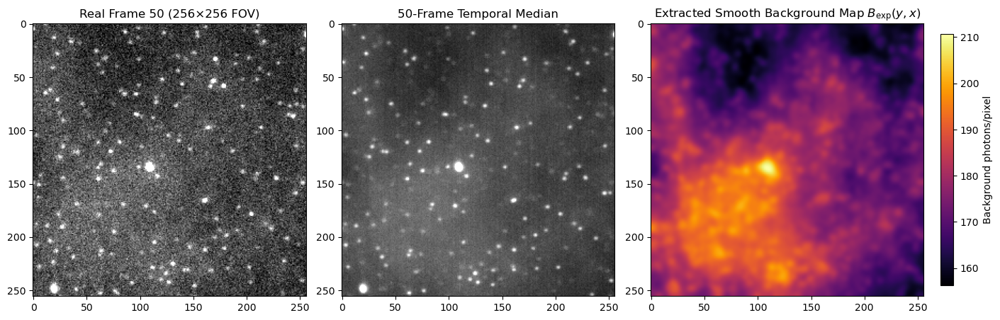

In [2]:
movie_path = project / 'data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3.tif'
frame_index = 50
window_size = 50
target_channel = 'right'

# Central 256×256 FOV (or set fov_y0, fov_y1, fov_x0, fov_x1 = 0, 684, 0, 428 for the full channel!)
fov_y0, fov_y1 = 220, 476
fov_x0, fov_x1 = 86, 342
fov_h, fov_w = fov_y1 - fov_y0, fov_x1 - fov_x0

# Load parameters & camera converter
example = project / 'experimental_data_workflow'
own_cal_path = project / 'data/bead_calibration/Beadzstack_3DLens_3dcal.mat'
param = decode.utils.param_io.load_params(str(example / 'param_run.yaml'))
param.InOut.calibration_file = str(own_cal_path)
param.Hardware.device = 'cpu'
param.Hardware.device_simulation = 'cpu'

param.Camera.px_size = [117.0, 117.0]
param.Camera.baseline = 400.0
param.Camera.e_per_adu = 0.46
param.Camera.em_gain = None
param.Camera.read_sigma = 1.6
param.Camera.qe = 0.8
param.Camera.spur_noise = 0.0
param.Camera.convert2photons = True

camera = decode.simulation.camera.Photon2Camera.parse(param)

# Read 50 frames around frame_index to compute the temporal median background
with tifffile.TiffFile(movie_path) as tif:
    n_total = len(tif.pages)
    start_f = max(0, frame_index - window_size // 2)
    end_f = min(n_total, start_f + window_size)
    stack_adu = np.stack([tif.pages[i].asarray() for i in range(start_f, end_f)]).astype(np.float32)
    target_raw_adu = tif.pages[frame_index].asarray().astype(np.float32)

mid_w = stack_adu.shape[2] // 2
if target_channel == 'right':
    ch_stack_adu = stack_adu[:, fov_y0:fov_y1, mid_w + fov_x0 : mid_w + fov_x1]
    real_fov_adu = target_raw_adu[fov_y0:fov_y1, mid_w + fov_x0 : mid_w + fov_x1]
else:
    ch_stack_adu = stack_adu[:, fov_y0:fov_y1, fov_x0:fov_x1]
    real_fov_adu = target_raw_adu[fov_y0:fov_y1, fov_x0:fov_x1]

# Convert to DECODE photon units
real_photons = camera.backward(torch.from_numpy(real_fov_adu)).numpy()
ch_stack_photons = camera.backward(torch.from_numpy(ch_stack_adu)).numpy()

# Compute temporal median and filter out persistent fiducial beads so only diffuse background remains
raw_temporal_median = np.median(ch_stack_photons, axis=0)
spatial_med = median_filter(raw_temporal_median, size=15)
# Replace pixels that stick out > 20 photons above local spatial median (persistent beads)
bead_mask = (raw_temporal_median - spatial_med) > 20.0
clean_bg = np.where(bead_mask, spatial_med, raw_temporal_median)
# Mild Gaussian smoothing (sigma=2.5 px) removes residual finite-sample shot noise
bg_map_photons = gaussian_filter(clean_bg, sigma=2.5)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)
vmin, vmax = np.percentile(real_photons, [1, 99.5])
axes[0].imshow(real_photons, cmap='gray', vmin=vmin, vmax=vmax)
axes[0].set_title(f'Real Frame {frame_index} ({fov_h}×{fov_w} FOV)')
axes[1].imshow(raw_temporal_median, cmap='gray', vmin=vmin, vmax=vmax)
axes[1].set_title(f'{window_size}-Frame Temporal Median')
im = axes[2].imshow(bg_map_photons, cmap='inferno')
axes[2].set_title('Extracted Smooth Background Map $B_{\mathrm{exp}}(y, x)$')
fig.colorbar(im, ax=axes[2], label='Background photons/pixel', fraction=0.046)
plt.show()

## 2. Define `EmpiricalBackground` for DECODE's Simulator

DECODE's `decode.simulation.background.Background` interface requires a single method: `sample(size, device)`.
- When `size[-2:]` matches our extracted background map `(H, W)`, it returns the exact spatial background map (for direct frame-to-frame comparison).
- When `size[-2:]` is a smaller training patch (e.g., `40 × 40` during DECODE training), it **randomly crops a `40 × 40` window** from the experimental background pool, applies random horizontal/vertical flips and 90° rotations, and scales by a small random factor `scale_jitter` (e.g. `[0.9, 1.1]`) so the network sees realistic, spatially correlated backgrounds!

In [3]:
class EmpiricalBackground(decode.simulation.background.Background):
    """
    Spatially correlated background sampler backed by experimental temporal-median background maps.
    Supports both exact-frame matching (for visual evaluation) and random patch cropping (for DECODE training).
    """

    def __init__(self, bg_maps: np.ndarray, random_crop_and_augment: bool = False,
                 scale_jitter: tuple = (0.95, 1.05), forward_return: str = None):
        super().__init__(forward_return=forward_return)
        arr = np.asarray(bg_maps, dtype=np.float32)
        if arr.ndim == 2:
            arr = arr[np.newaxis, :, :]  # (N_maps, H, W)
        self.bg_pool = torch.from_numpy(arr)
        self.random_crop_and_augment = random_crop_and_augment
        self.scale_jitter = scale_jitter

    def sample(self, size: torch.Size, device=torch.device('cpu')) -> torch.Tensor:
        target_h, target_w = size[-2], size[-1]
        n_maps, pool_h, pool_w = self.bg_pool.shape

        # Determine number of frames to sample
        batch_shape = size[:-2]
        n_samples = int(np.prod(batch_shape)) if len(batch_shape) > 0 else 1

        if not self.random_crop_and_augment and target_h == pool_h and target_w == pool_w:
            # Exact spatial background map for direct visual comparison
            out = self.bg_pool[0].unsqueeze(0).repeat(n_samples, 1, 1)
        else:
            # Randomly crop and augment patches (used during 40×40 DECODE training)
            patches = []
            for _ in range(n_samples):
                m_idx = np.random.randint(0, n_maps)
                top = np.random.randint(0, max(1, pool_h - target_h + 1))
                left = np.random.randint(0, max(1, pool_w - target_w + 1))
                patch = self.bg_pool[m_idx, top : top + target_h, left : left + target_w].clone()
                if np.random.rand() < 0.5:
                    patch = torch.flip(patch, dims=[-1])
                if np.random.rand() < 0.5:
                    patch = torch.flip(patch, dims=[-2])
                if self.scale_jitter is not None:
                    scale = np.random.uniform(self.scale_jitter[0], self.scale_jitter[1])
                    patch = patch * scale
                patches.append(patch)
            out = torch.stack(patches, dim=0)

        return out.reshape(size).to(device)

print('EmpiricalBackground class ready.')

EmpiricalBackground class ready.


## 3. Side-by-Side Comparison: Real Frame vs. `UniformBackground` vs. `EmpiricalBackground`

We generate the **exact same set of simulated emitters** (`em`) and pass them through:
1. DECODE's default `UniformBackground` (flat scalar background)
2. Our new `EmpiricalBackground` (spatially structured background from Section 1)

Notice how the **left shoulder (`130–170` photons)** and **overall width** of the pixel intensity histogram—as well as the visual shading across the field of view—now match the experimental frame!

Real FOV percentiles (5, 50, 95, 99.5)         : [145.5 176.5 216.8 276.6]
Uniform Bg Sim percentiles (5, 50, 95, 99.5)   : [151.8 177.1 208.2 259.3]
Empirical Bg Sim percentiles (5, 50, 95, 99.5) : [148.9 178.8 215.6 262.8]


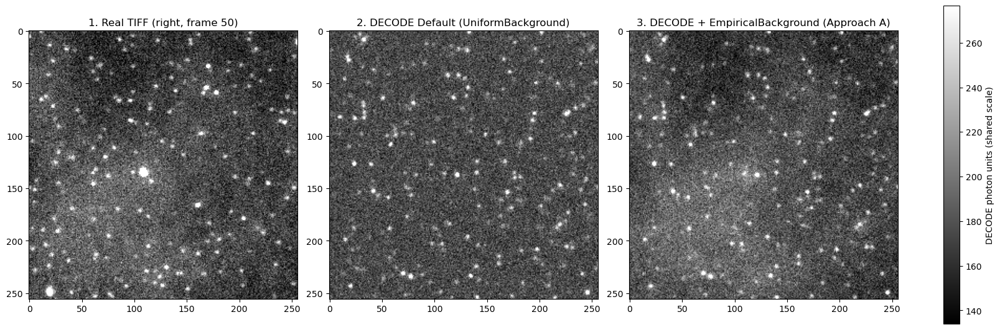

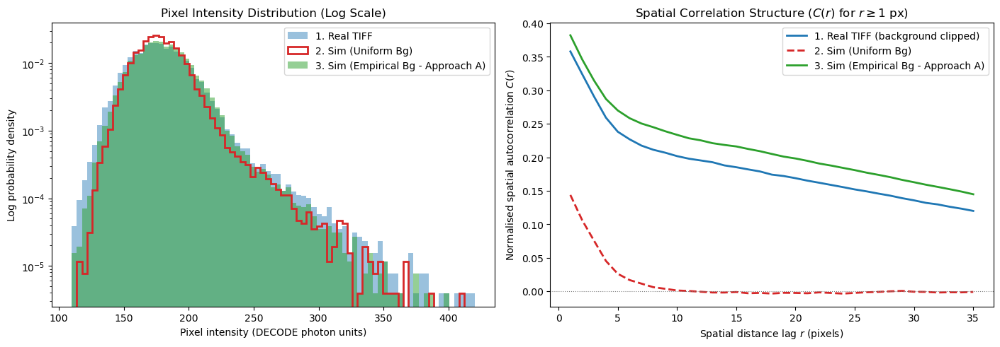

In [6]:
emitters_per_fov = 380
# In RegistrationCheck, in-frame single-molecule photons have median ~973 (p90=1692, p95=2231).
# Since EmitterSamplerBlinking (lifetime=1.0) splits photons across frames, pre-split mu=1800 gives ~950-1000 in-frame photons.
brightness_mean_std = [1800.0, 750.0]
z_range_nm = [-200.0, 200.0]
seed = 67

param.Simulation.emitter_av = emitters_per_fov
param.Simulation.bg_uniform = [float(np.percentile(bg_map_photons, 20)), float(np.percentile(bg_map_photons, 80))]
param.Simulation.intensity_mu_sig = brightness_mean_std
param.Simulation.emitter_extent[0] = [-0.5, fov_h - 0.5]
param.Simulation.emitter_extent[1] = [-0.5, fov_w - 0.5]
param.Simulation.emitter_extent[2] = z_range_nm
param.Simulation.psf_extent[0] = [-0.5, fov_h - 0.5]
param.Simulation.psf_extent[1] = [-0.5, fov_w - 0.5]
param.Simulation.img_size = [fov_h, fov_w]
param.HyperParameter.pseudo_ds_size = 0
param.TestSet.test_size = 0

# Build simulator and sample one EmitterSet
torch.manual_seed(seed)
np.random.seed(seed)
sim_uniform, _ = setup_random_simulation(param)
emitters = sim_uniform.em_sampler()

# Forward identical emitters through (A) UniformBackground and (B) EmpiricalBackground
torch.manual_seed(seed + 1)
frames_uni, bg_uni = sim_uniform.forward(emitters)
sim_uni_photons = frames_uni[0].detach().cpu().numpy()

sim_empirical = decode.simulation.simulator.Simulation(
    psf=sim_uniform.psf,
    em_sampler=sim_uniform.em_sampler,
    background=EmpiricalBackground(bg_map_photons, random_crop_and_augment=False),
    noise=sim_uniform.noise,
    frame_range=sim_uniform.frame_range,
)
torch.manual_seed(seed + 1)
frames_emp, bg_emp = sim_empirical.forward(emitters)
sim_emp_photons = frames_emp[0].detach().cpu().numpy()

print(f'Real FOV percentiles (5, 50, 95, 99.5)         : {np.percentile(real_photons, [5, 50, 95, 99.5]).round(1)}')
print(f'Uniform Bg Sim percentiles (5, 50, 95, 99.5)   : {np.percentile(sim_uni_photons, [5, 50, 95, 99.5]).round(1)}')
print(f'Empirical Bg Sim percentiles (5, 50, 95, 99.5) : {np.percentile(sim_emp_photons, [5, 50, 95, 99.5]).round(1)}')

# --- Plot 1: 3-Way Side-by-Side Frame Comparison ---
vmin_p, vmax_p = np.percentile(real_photons, [1, 99.5])
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)
axes[0].imshow(real_photons, cmap='gray', vmin=vmin_p, vmax=vmax_p)
axes[0].set_title(f'1. Real TIFF ({target_channel}, frame {frame_index})')
axes[1].imshow(sim_uni_photons, cmap='gray', vmin=vmin_p, vmax=vmax_p)
axes[1].set_title('2. DECODE Default (UniformBackground)')
im2 = axes[2].imshow(sim_emp_photons, cmap='gray', vmin=vmin_p, vmax=vmax_p)
axes[2].set_title('3. DECODE + EmpiricalBackground (Approach A)')
fig.colorbar(im2, ax=axes, label='DECODE photon units (shared scale)', fraction=0.025)
plt.show()

# --- Plot 2: Histogram & Spatial Autocorrelation Comparison ---
def radial_autocorrelation(img, max_lag=30):
    """Compute normalised 2D spatial autocorrelation vs radial pixel lag."""
    z = img - img.mean()
    f = np.fft.fft2(z)
    ac = np.fft.ifft2(np.abs(f) ** 2).real
    ac /= ac[0, 0]
    ac = np.fft.fftshift(ac)
    cy, cx = np.array(ac.shape) // 2
    yy, xx = np.indices(ac.shape)
    r = np.rint(np.hypot(yy - cy, xx - cx)).astype(int)
    lags = np.arange(1, max_lag + 1)
    prof = [ac[r == d].mean() for d in lags]
    return lags, np.array(prof)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)

# Panel A: Log-scale pixel intensity histogram
bins = np.linspace(110, 420, 80)
axes[0].hist(real_photons.ravel(), bins=bins, density=True, alpha=0.45, label='1. Real TIFF', color='tab:blue')
axes[0].hist(sim_uni_photons.ravel(), bins=bins, density=True, histtype='step', linewidth=2.0, label='2. Sim (Uniform Bg)', color='tab:red')
axes[0].hist(sim_emp_photons.ravel(), bins=bins, density=True, alpha=0.50, label='3. Sim (Empirical Bg - Approach A)', color='tab:green')
axes[0].set_yscale('log')
axes[0].set_xlabel('Pixel intensity (DECODE photon units)')
axes[0].set_ylabel('Log probability density')
axes[0].set_title('Pixel Intensity Distribution (Log Scale)')
axes[0].legend()

# Panel B: Spatial autocorrelation of background pixels (clipping bright spots at 95th percentile)
for name, arr, col, ls in [
    ('1. Real TIFF (background clipped)', np.clip(real_photons, None, np.percentile(real_photons, 95)), 'tab:blue', '-'),
    ('2. Sim (Uniform Bg)', np.clip(sim_uni_photons, None, np.percentile(sim_uni_photons, 95)), 'tab:red', '--'),
    ('3. Sim (Empirical Bg - Approach A)', np.clip(sim_emp_photons, None, np.percentile(sim_emp_photons, 95)), 'tab:green', '-'),
]:
    lags, ac_prof = radial_autocorrelation(arr, max_lag=35)
    axes[1].plot(lags, ac_prof, label=name, color=col, linestyle=ls, linewidth=2.0)

axes[1].axhline(0, color='gray', linewidth=0.8, linestyle=':')
axes[1].set_xlabel('Spatial distance lag $r$ (pixels)')
axes[1].set_ylabel('Normalised spatial autocorrelation $C(r)$')
axes[1].set_title('Spatial Correlation Structure ($C(r)$ for $r \geq 1$ px)')
axes[1].legend()
plt.show()

## 4. Reference Notes: Approach B (Parametric Multi-Scale Spatially Correlated Background & Heavy-Tailed Emitter Model)

While **Approach A (`EmpiricalBackground`)** directly samples the sliding-window temporal median from real TIFFs, **Approach B** constructs a fully synthetic, parametric generative model for both the spatially structured background and the heavy-tailed emitter brightness distribution. This is ideal if we want to generate unlimited synthetic training frames with randomised illumination geometries without being tied to a single fixed FOV.

### Part 1: Multi-Scale Spatially Correlated Background ($B(y, x)$)

In experimental SMLM frames, the photon background before shot noise is not a flat constant $B_0$; it exhibits spatial correlation across two distinct physical length scales, visible in the radial autocorrelation curve $C(r)$ above:

1. **Large-scale illumination profile ($\sigma_{\text{illum}} \approx 40\text{–}80\text{ px}$):** Non-uniform Gaussian/TIRF laser excitation and vignette roll-off across the FOV.
2. **Medium-scale cellular/autofluorescence haze ($\sigma_{\text{cell}} \approx 5\text{–}12\text{ px}$):** Out-of-focus fluorophores, coverslip scatter, and local sample autofluorescence.

We can generate a random realisation of this background field on each frame (or sub-stack) as a sum of Gaussian-filtered white noise fields:

$$
B(y, x) = \mu_B + \alpha_{\text{illum}} \cdot \left(G_{\sigma_{\text{illum}}} * W_1(y, x)\right) + \alpha_{\text{cell}} \cdot \left(G_{\sigma_{\text{cell}}} * W_2(y, x)\right)
$$

where:
- $W_1, W_2 \sim \mathcal{N}(0, 1)$ are independent 2D standard normal white-noise fields, convolved with 2D Gaussian kernels $G_\sigma$ and normalised to unit variance.
- $\mu_B$ is the mean background level in DECODE photon units (e.g. $\sim 170$ photons/pixel in the central FOV).
- $\sigma_{\text{illum}}, \sigma_{\text{cell}}$ and the amplitude weights $\alpha_{\text{illum}}, \alpha_{\text{cell}}$ are fitted directly to the experimental background map's radial autocorrelation $C_{\text{exp}}(r)$ and spatial variance $\sigma_B^2 = \alpha_{\text{illum}}^2 + \alpha_{\text{cell}}^2$ (since a 2D Gaussian filter of width $\sigma$ produces an autocorrelation $C(r) = \exp(-r^2 / 4\sigma^2)$).
- Finally, $B(y, x)$ is clipped at $\ge 0$ and passed through DECODE's `Photon2Camera` pipeline, which applies Poisson shot noise $\text{Poisson}(B(y, x) + I_{\text{PSF}}(y, x))$ and sCMOS Gaussian read noise.

### Part 2: Heavy-Tailed Emitter Brightness Distribution (Matching the Right Histogram Tail)

Even when the background distribution matches (`p5`–`p50`), the log-scale pixel histogram shows that real SMLM frames have a heavier bright-pixel tail (`250–400+` photons/pixel) than a standard Gaussian emitter intensity model (`IntensityDist`). In SMLM, single-molecule photon counts per frame follow a right-skewed distribution due to:
- Exponentially distributed fluorophore ON-time durations within a camera exposure frame, and
- Persistent/multi-frame emitters or fiducial markers that remain bright across multiple frames.

To capture this in Approach B:
1. **Fit a Log-Normal or Gamma distribution** to the empirical integrated spot photon distribution (from Picasso localisations on the residual and background frames):
   $$
   N_{\text{photons}} \sim \text{LogNormal}(\mu_{\ln}, \sigma_{\ln}^2) \quad \text{or} \quad \text{Gamma}(k, \theta)
   $$
2. **Subclass `decode.simulation.emitter_generator` or `PriorSMLM`** to sample emitter `intensity` from this Log-Normal/Gamma distribution (or a two-component mixture of transient blinking fluorophores + a small fraction of bright persistent emitters) instead of a symmetric Gaussian.

## 5. Multi-Scale Training Patch Simulations ($40 \times 40$, $64 \times 64$, and $100 \times 100$)

Because DECODE's `SigmaMUNet` is fully convolutional (requiring only that patch dimensions are divisible by $4$), we can train on randomly cropped and augmented patches (`random_crop_and_augment=True`) of size $40 \times 40$, $64 \times 64$, or $100 \times 100$ sampled from `bg_map_photons`, while keeping emitter density constant ($\approx 2.24 \times 10^{-3}\text{ emitters/px}^2$, matching the 147 emitters in the $256 \times 256$ FOV).

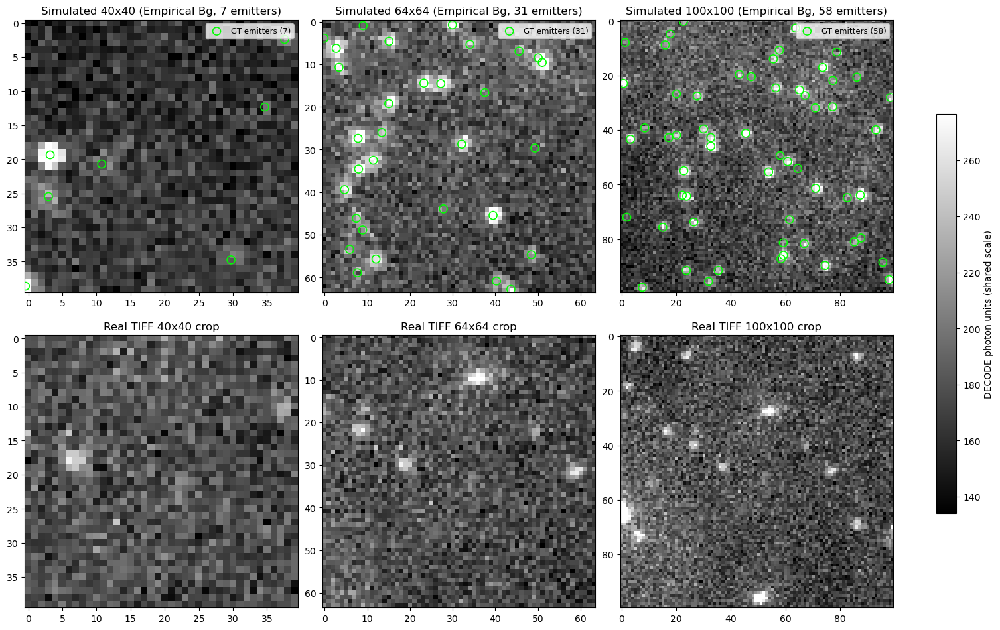

In [10]:
patch_sizes = [40, 64, 100]
base_density = emitters_per_fov / (fov_h * fov_w)  # Match exact emitter density from Section 3

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), constrained_layout=True)
vmin_p, vmax_p = np.percentile(real_photons, [1, 99.5])

np.random.seed(seed)
torch.manual_seed(seed)

for col, sz in enumerate(patch_sizes):
    # 1. Configure DECODE simulation for (sz x sz) patch using exact Section 3 brightness & z-range
    p_patch = decode.utils.param_io.load_params(str(project / 'experimental_data_workflow' / 'param_run.yaml'))
    p_patch.InOut.calibration_file = str(own_cal_path)
    p_patch.Hardware.device = 'cpu'
    p_patch.Hardware.device_simulation = 'cpu'
    p_patch.Camera.baseline = 400.0
    p_patch.Camera.e_per_adu = 0.46
    p_patch.Camera.em_gain = None
    p_patch.Camera.qe = 0.8
    p_patch.Camera.read_sigma = 1.6
    p_patch.Camera.spur_noise = 0.0
    p_patch.Camera.px_size = [117.0, 117.0]
    p_patch.Camera.convert2photons = True
    p_patch.Simulation.mode = 'acquisition'
    p_patch.Simulation.img_size = [sz, sz]
    p_patch.Simulation.psf_extent = [[-0.5, sz - 0.5], [-0.5, sz - 0.5], None]
    p_patch.Simulation.emitter_extent = [[-0.5, sz - 0.5], [-0.5, sz - 0.5], z_range_nm]
    p_patch.Simulation.emitter_av = max(3.0, round(base_density * sz * sz, 1))
    p_patch.Simulation.intensity_mu_sig = [1800.0, 750.0]  # Pre-split photons so in-frame median is ~950-1000 photons
    p_patch.Simulation.lifetime_avg = 1.0
    p_patch.HyperParameter.pseudo_ds_size = 0
    p_patch.TestSet.test_size = 0
    p_patch.TestSet.frame_extent = p_patch.Simulation.psf_extent
    p_patch.TestSet.img_size = [sz, sz]

    sim_base, _ = setup_random_simulation(p_patch)
    sim_patch = decode.simulation.simulator.Simulation(
        psf=sim_base.psf,
        em_sampler=sim_base.em_sampler,
        background=EmpiricalBackground(
            bg_map_photons,
            random_crop_and_augment=True,
            scale_jitter=(0.95, 1.05),
        ),
        noise=sim_base.noise,
        frame_range=[0, 0],
    )

    em_p, frames_p, bg_p = sim_patch.sample()
    sim_img = frames_p[0].detach().cpu().numpy()
    # Filter to emitters active in frame 0 with >=250 in-frame photons (excluding out-of-frame/tail blinks)
    em_f0 = em_p.get_subset_frame(0, 0)
    vis_mask = em_f0.phot >= 250.0
    em_xyz = em_f0.xyz_px[vis_mask].detach().cpu().numpy()

    # 2. Extract a real experimental crop of the same size (sz x sz)
    r_top = max(0, 120 - sz // 2)
    r_left = max(0, 160 - sz // 2)
    real_crop = real_photons[r_top : r_top + sz, r_left : r_left + sz]

    # Top row: Simulated patch with EmpiricalBackground + Ground-Truth emitter positions
    im = axes[0, col].imshow(sim_img, cmap='gray', vmin=vmin_p, vmax=vmax_p)
    if len(em_xyz) > 0:
        axes[0, col].scatter(
            em_xyz[:, 1], em_xyz[:, 0],
            s=75, facecolors='none', edgecolors='lime', linewidths=1.2,
            label=f'GT emitters ({len(em_xyz)})'
        )
        axes[0, col].legend(loc='upper right', fontsize=8.5, framealpha=0.8)
    axes[0, col].set_title(f'Simulated {sz}x{sz} (Empirical Bg, {len(em_xyz)} emitters)')

    # Bottom row: Real experimental crop of the same size
    axes[1, col].imshow(real_crop, cmap='gray', vmin=vmin_p, vmax=vmax_p)
    axes[1, col].set_title(f'Real TIFF {sz}x{sz} crop')

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.65, label='DECODE photon units (shared scale)')
plt.show()

## 6. Testing Background Extraction Across `low_density_examples/` & `high_density_examples/`

Here we test the exact same 3-step background extraction pipeline (**50-frame temporal median $\rightarrow$ `median_filter(size=15)` persistent-emitter inpainting $\rightarrow$ `gaussian_filter(sigma=2.5)`**) on random frames sampled from 6 different movies across `data/low_density_examples/` and `data/high_density_examples/`.

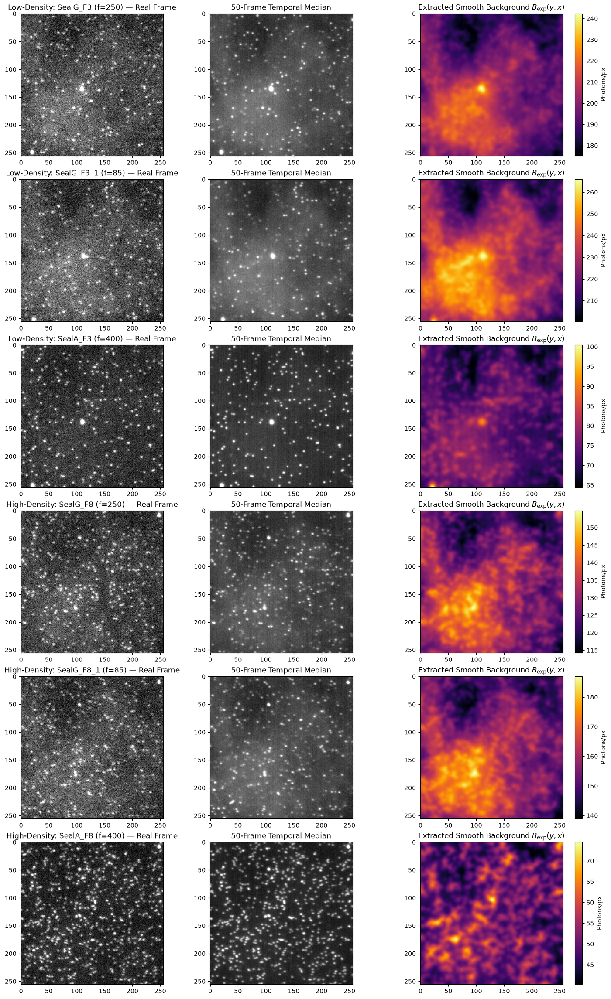

In [8]:
sample_specs = [
    ('Low-Density: SealG_F3 (f=250)', 'data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3.tif', 250),
    ('Low-Density: SealG_F3_1 (f=85)', 'data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3_1.tif', 85),
    ('Low-Density: SealA_F3 (f=400)', 'data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealA_F3.tif', 400),
    ('High-Density: SealG_F8 (f=250)', 'data/high_density_examples/RegistrationCheck_HighDensity_GapT_Exp1_GapT_SealG_F8.tif', 250),
    ('High-Density: SealG_F8_1 (f=85)', 'data/high_density_examples/RegistrationCheck_HighDensity_GapT_Exp1_GapT_SealG_F8_1.tif', 85),
    ('High-Density: SealA_F8 (f=400)', 'data/high_density_examples/RegistrationCheck_HighDensity_GapT_Exp1_GapT_SealA_F8.tif', 400),
]

fig, axes = plt.subplots(len(sample_specs), 3, figsize=(14, 3.8 * len(sample_specs)), constrained_layout=True)
conv_factor = 0.46 / 0.8  # e_per_adu / qe

for row, (label, rel_path, f_idx) in enumerate(sample_specs):
    t_path = project / rel_path
    with tifffile.TiffFile(t_path) as tif:
        n_pages = len(tif.pages)
        s_f = max(0, min(f_idx - 25, n_pages - 50))
        e_f = min(n_pages, s_f + 50)
        st_adu = np.stack([tif.pages[i].asarray() for i in range(s_f, e_f)]).astype(np.float32)
        fr_adu = tif.pages[f_idx].asarray().astype(np.float32)

    # Extract central 256x256 FOV of right channel and convert to DECODE photon units
    mw = st_adu.shape[2] // 2
    st_phot = (st_adu[:, fov_y0:fov_y1, mw + fov_x0 : mw + fov_x1] - 400.0) * conv_factor
    fr_phot = (fr_adu[fov_y0:fov_y1, mw + fov_x0 : mw + fov_x1] - 400.0) * conv_factor

    # 1. 50-frame temporal median
    t_med = np.median(st_phot, axis=0)
    # 2. Remove persistent emitters / fiducial beads that exceed local spatial median
    sp_med = median_filter(t_med, size=15)
    b_mask = (t_med - sp_med) > 15.0
    cl_bg = np.where(b_mask, sp_med, t_med)
    # 3. Smooth residual finite-window shot noise
    sm_bg = gaussian_filter(cl_bg, sigma=2.5)

    v_min, v_max = np.percentile(fr_phot, [1, 99.5])
    axes[row, 0].imshow(fr_phot, cmap='gray', vmin=v_min, vmax=v_max)
    axes[row, 0].set_title(f'{label} — Real Frame')

    axes[row, 1].imshow(t_med, cmap='gray', vmin=v_min, vmax=v_max)
    axes[row, 1].set_title('50-Frame Temporal Median')

    im_bg = axes[row, 2].imshow(sm_bg, cmap='inferno')
    axes[row, 2].set_title('Extracted Smooth Background $B_{\\mathrm{exp}}(y, x)$')
    fig.colorbar(im_bg, ax=axes[row, 2], label='Photons/px', fraction=0.046)

plt.show()

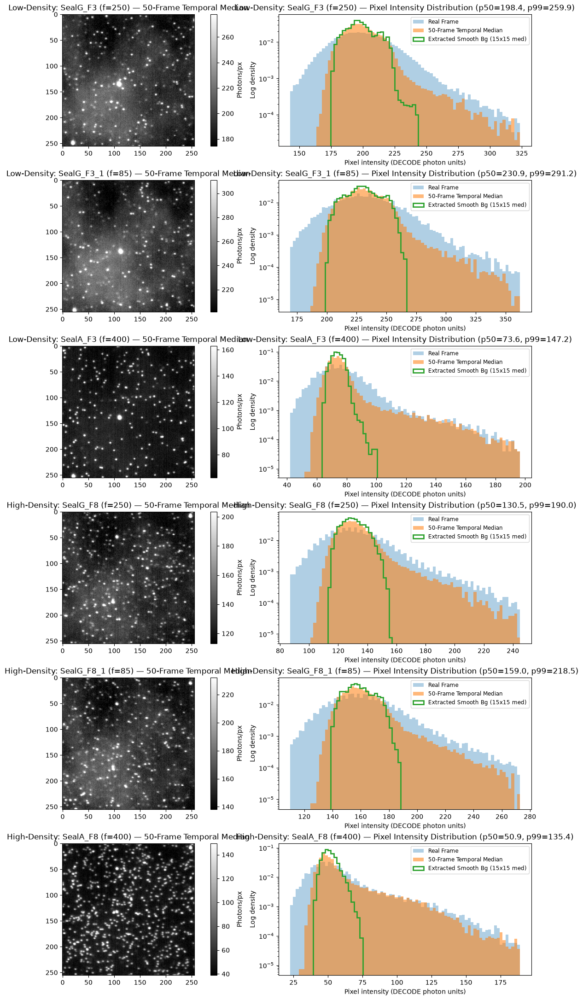

In [9]:
# Side-by-side: 50-Frame Temporal Median Image vs. Pixel Intensity Histogram (Log Scale)
fig, axes = plt.subplots(len(sample_specs), 2, figsize=(13, 3.6 * len(sample_specs)), constrained_layout=True)

for row, (label, rel_path, f_idx) in enumerate(sample_specs):
    t_path = project / rel_path
    with tifffile.TiffFile(t_path) as tif:
        n_pages = len(tif.pages)
        s_f = max(0, min(f_idx - 25, n_pages - 50))
        e_f = min(n_pages, s_f + 50)
        st_adu = np.stack([tif.pages[i].asarray() for i in range(s_f, e_f)]).astype(np.float32)
        fr_adu = tif.pages[f_idx].asarray().astype(np.float32)

    mw = st_adu.shape[2] // 2
    st_phot = (st_adu[:, fov_y0:fov_y1, mw + fov_x0 : mw + fov_x1] - 400.0) * conv_factor
    fr_phot = (fr_adu[fov_y0:fov_y1, mw + fov_x0 : mw + fov_x1] - 400.0) * conv_factor

    t_med = np.median(st_phot, axis=0)
    sp_med = median_filter(t_med, size=15)
    b_mask = (t_med - sp_med) > 15.0
    cl_bg = np.where(b_mask, sp_med, t_med)
    sm_bg = gaussian_filter(cl_bg, sigma=2.5)

    # Left column: 50-Frame Temporal Median image
    v_min, v_max = np.percentile(t_med, [1, 99.5])
    im_tm = axes[row, 0].imshow(t_med, cmap='gray', vmin=v_min, vmax=v_max)
    axes[row, 0].set_title(f'{label} — 50-Frame Temporal Median')
    fig.colorbar(im_tm, ax=axes[row, 0], label='Photons/px', fraction=0.046)

    # Right column: Pixel Intensity Histogram (Real vs. Temporal Median vs. Extracted Smooth Bg)
    h_min = float(np.percentile(fr_phot, 0.2))
    h_max = float(np.percentile(fr_phot, 99.8))
    bins = np.linspace(h_min, h_max, 80)

    axes[row, 1].hist(fr_phot.ravel(), bins=bins, density=True, alpha=0.35, color='tab:blue', label='Real Frame')
    axes[row, 1].hist(t_med.ravel(), bins=bins, density=True, alpha=0.55, color='tab:orange', label='50-Frame Temporal Median')
    axes[row, 1].hist(sm_bg.ravel(), bins=bins, density=True, histtype='step', linewidth=2.0, color='tab:green', label='Extracted Smooth Bg (15x15 med)')
    axes[row, 1].set_yscale('log')
    axes[row, 1].set_xlabel('Pixel intensity (DECODE photon units)')
    axes[row, 1].set_ylabel('Log density')
    axes[row, 1].set_title(f'{label} — Pixel Intensity Distribution (p50={np.median(t_med):.1f}, p99={np.percentile(t_med, 99):.1f})')
    axes[row, 1].legend(loc='upper right', fontsize=8.5)

plt.show()

## 7. Option 2: Poisson-Prior $\kappa\sigma$-Clipped Dilated-Mask Inpainting via Normalized Convolution

To prevent large fiducial beads or dense clusters of persistent emitters from biasing the local $15 \times 15$ spatial median upward, we separate the **left true-background bulk** of the temporal-median histogram from the **heavy right tail** using a physically grounded Poisson shot-noise prior, dilate the resulting mask to swallow faint PSF wings/halos, and interpolate across only the masked holes using **Normalized Gaussian Convolution**.

### Mathematical Formulation & Literature Basis

1. **Laplace Asymptotic Variance of the $N$-Frame Poisson Sample Median** *(Laplace, 1818; Rider, 1960; Stuart & Ord, 1994)*:  
   For an uncontaminated background pixel with true local photon rate $\mu_{\mathrm{bg}}(y, x)$ and single-frame variance $\sigma_{\mathrm{single}}^2(y, x) = \mu_{\mathrm{bg}}(y, x) + \sigma_{\mathrm{read}}^2$, the sample median $I_{\mathrm{med}}(y, x)$ across $N = 50$ independent frames is asymptotically Gaussian with variance:
   $$\sigma_{\mathrm{t\_med, Poisson}}^2(y, x) = \frac{1}{4 N \, [f(\mu_{\mathrm{bg}})]^2} = \frac{\pi}{2 N} \, \sigma_{\mathrm{single}}^2(y, x) \approx \frac{1.5708}{N} \, \mu_{\mathrm{bg}}(y, x)$$
   To account for sub-25-frame emitter blinking and sCMOS read-noise without being biased by the right tail, we estimate the local uncontaminated baseline from the **25th spatial percentile** $P_{25}(y, x)$ over a $25 \times 25$ window and the empirical left-tail spread $\sigma_{\mathrm{left}}$ from the lower quantile spacing $(P_{25} - P_{5}) / 0.9704$, taking:
   $$\sigma_{\mathrm{bg}}(y, x) = \max\!\left(\sigma_{\mathrm{t\_med, Poisson}}(y, x),\; \operatorname{median}(\sigma_{\mathrm{left}})\right), \qquad \mu_{\mathrm{bg}}(y, x) = P_{25}(y, x) + 0.6745 \, \sigma_{\mathrm{bg}}(y, x)$$

   > **Intuitive Breakdown of the Left-Tail Quantile Equations:**
   > - **Why only use the left side of the histogram ($P_5$ and $P_{25}$)?** The right half of the temporal-median histogram (above the 50th percentile) is contaminated by a heavy tail of bright fiducial beads and persistent emitters, whereas the left half is a clean Gaussian bell curve coming from genuinely empty background pixels.
   > - **Why $\mu_{\mathrm{bg}}(y, x) = P_{25}(y, x) + 0.6745\,\sigma_{\mathrm{bg}}(y, x)$?** Taking the **25th spatial percentile** $P_{25}(y,x)$ over a $25 \times 25$ window means up to 75% of the window could be covered by bright beads without corrupting $P_{25}$. However, in any Gaussian distribution $\mathcal{N}(\mu, \sigma)$, the 25th percentile sits slightly below the true center peak ($\mu$) at $z_{0.25} = -0.6745\,\sigma$ (i.e., $P_{25} = \mu_{\mathrm{bg}} - 0.6745\,\sigma_{\mathrm{bg}}$). Adding back $+0.6745\,\sigma_{\mathrm{bg}}$ shifts $P_{25}$ right back to the true center peak of the uncontaminated background bell curve.
   > - **What is "sub-25-frame blinking" and why $(P_{25} - P_5) / 0.9704$?** If a normal, non-persistent molecule blinks ON for e.g. $10$ out of $50$ frames ($< 25$ frames), the 50-frame temporal median does not jump to the emitter's peak brightness, but those 10 bright frames at the top of the 50 sorted frames shift the middle (25th) sorted value upward by a few photons, making the background bell curve slightly wider than the theoretical 0-emitter Poisson floor $\sigma_{\mathrm{t\_med, Poisson}}$. In any Gaussian $\mathcal{N}(\mu, \sigma)$, $P_{25}$ sits at $z_{0.25} = -0.6745\,\sigma$ and $P_5$ sits at $z_{0.05} = -1.6449\,\sigma$, so the distance between them is $(-0.6745) - (-1.6449) = 0.9704\,\sigma$. Dividing $(P_{25} - P_5)$ by $0.9704$ therefore measures the exact standard deviation $\sigma_{\mathrm{left}}$ of the uncontaminated left side of the bell curve.
   > - **What does $\sigma_{\mathrm{bg}} \approx 3\text{--}5\text{ photons}$ mean in terms of pixel intensity?** In our plots, pixel intensity is already converted into **DECODE photon units** ($\text{photons/px}$), where $\text{Photons} = (\text{ADU} - 400.0) \times \frac{0.46}{0.80} = (\text{ADU} - 400.0) \times 0.575$. Thus, $1\text{ photon/px} = 1.74\text{ raw camera ADU counts}$ above the 400 ADU baseline, and a temporal-median spread of $\sigma_{\mathrm{bg}} \approx 3\text{--}5\text{ photons/px}$ means the background noise in the 50-frame temporal median fluctuates by only $\pm 3\text{--}5\text{ units}$ on the histogram x-axis (equivalent to $\pm 5.2\text{--}8.7\text{ ADU}$ on the raw 16-bit TIFF).

2. **$\kappa\sigma$-Clipping & Morphological Mask Dilation to Capture PSF Halos** *(Bertin & Arnouts, 1996; Hoogendoorn et al., 2014; Akhlaghi & Ichikawa, 2015)*:  
   Any pixel in the right tail exceeding $I_{\mathrm{med}}(y, x) > \mu_{\mathrm{bg}}(y, x) + \kappa \, \sigma_{\mathrm{bg}}(y, x)$ (with $\kappa = 2.5$) is flagged as a persistent emitter or fiducial bead ($M_{\mathrm{raw}}(y, x) = 1$). Because bright fiducial beads possess wide Airy skirts/halos that gently decay below threshold $\kappa\sigma_{\mathrm{bg}}$, we morphologically dilate the binary mask by a disk of radius $r = 3\text{ px}$ ($M_{\mathrm{dil}} = M_{\mathrm{raw}} \oplus D_r$) so that sub-threshold halo photons are completely excluded before smoothing.

3. **Normalized Gaussian Convolution Over Unmasked Background Pixels** *(Knutsson & Westin, 1993)*:  
   Rather than applying a large spatial filter to the entire image (which would over-smooth true background structure) or replacing masked pixels with a single global mean (which would ignore spatial illumination gradients), we define the binary validity weight $W(y, x) = 1 - M_{\mathrm{dil}}(y, x) \in \{0, 1\}$ and compute the inpainted hole-fill via **Normalized Convolution**:
   $$B_{\mathrm{fill}}(y, x) = \frac{(I_{\mathrm{med}} \cdot W) * G_{\sigma_{\mathrm{inp}}}}{W * G_{\sigma_{\mathrm{inp}}}}$$
   Masked pixels ($W = 0$) contribute **zero** photon weight regardless of how bright or wide a bead is, while unmasked pixels ($W = 1$) remain untouched prior to the final gentle $\sigma = 2.5\text{ px}$ Gaussian polish.

### References
- **Laplace, P. S.** (1818). *Théorie analytique des probabilités* (Supplément 2). Courcier, Paris.
- **Rider, P. R.** (1960). Variance of the median of small samples from several special populations. *Journal of the American Statistical Association*, 55(289), 148–150.
- **Knutsson, H., & Westin, C.-F.** (1993). Normalized and differential convolution: Methods for interpolation and filtering of incomplete and uncertain data. *Proceedings of IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 515–523.
- **Bertin, E., & Arnouts, S.** (1996). SExtractor: Software for source extraction. *Astronomy and Astrophysics Supplement Series*, 117(2), 393–404.
- **Hoogendoorn, E., Crosby, K. C., Leyton-Puig, D., Breedijk, R. M., Jalink, K., Gadella, T. W., & Postma, M.** (2014). The fidelity of stochastic single-molecule super-resolution reconstructions critically depends upon robust background estimation. *Scientific Reports*, 4, 3854.
- **Akhlaghi, M., & Ichikawa, T.** (2015). Noise-based detection and segmentation of nebulous objects. *The Astrophysical Journal Supplement Series*, 220(1), 1.

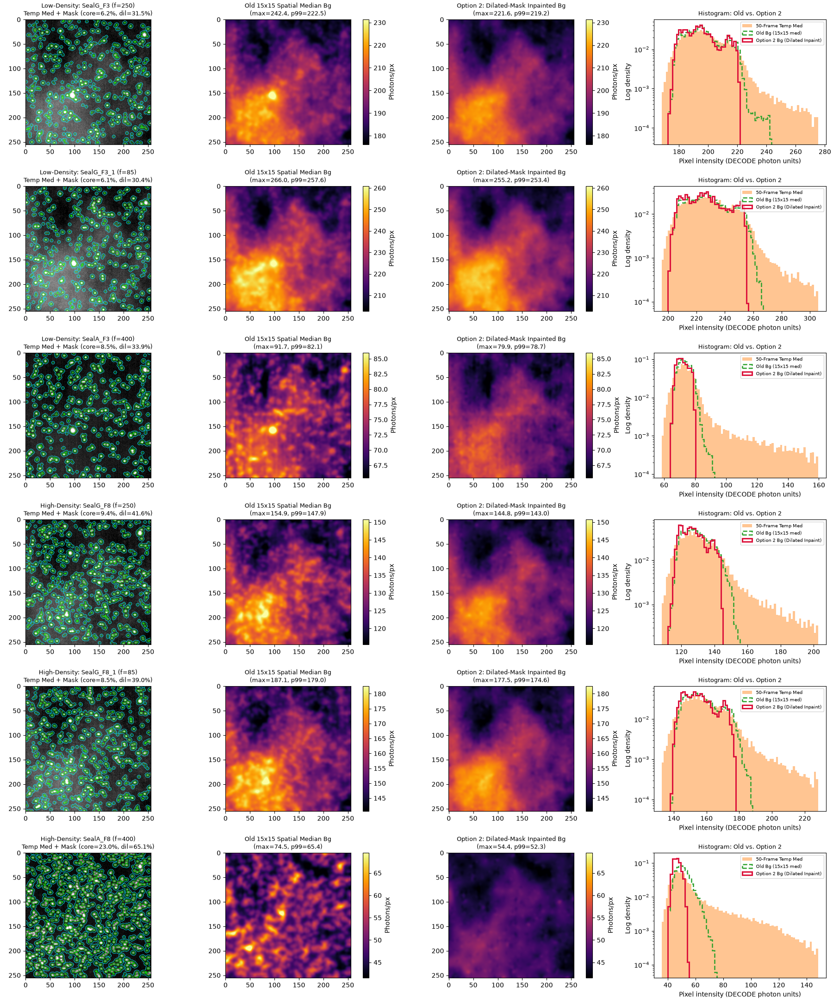

In [10]:
from scipy.ndimage import binary_dilation, percentile_filter

def extract_bg_option2(t_med, n_frames=50, kappa=2.5, dilate_px=3, inpaint_sigma=7.0, smooth_sigma=2.5):
    """Option 2: Poisson-prior kappa-sigma dilated-mask inpainting via Normalized Gaussian Convolution."""
    # 1. Uncontaminated local baseline from 25th percentile + left-tail spread (p25 - p5) / 0.9704
    p25_local = percentile_filter(t_med, percentile=25, size=25)
    p05_local = percentile_filter(t_med, percentile=5, size=25)
    sigma_left_local = (p25_local - p05_local) / 0.9704

    # Laplace asymptotic Poisson std for sample median of N frames: sqrt((pi / (2*N)) * mu_bg)
    sigma_poisson_local = np.sqrt((np.pi / (2.0 * n_frames)) * np.maximum(p25_local, 1.0))
    sigma_bg = np.maximum(sigma_poisson_local, float(np.median(sigma_left_local)))

    # Unbiased local background mode/median estimate (for Gaussian, p50 - p25 = 0.6745 * sigma)
    mu_bg_local = p25_local + 0.6745 * sigma_bg

    # 2. Flag right-tail outlier pixels (> mu_bg_local + kappa * sigma_bg) and dilate by disk of radius dilate_px
    raw_mask = (t_med - mu_bg_local) > (kappa * sigma_bg)
    y_g, x_g = np.ogrid[-dilate_px : dilate_px + 1, -dilate_px : dilate_px + 1]
    disk_struct = (x_g**2 + y_g**2) <= dilate_px**2
    dilated_mask = binary_dilation(raw_mask, structure=disk_struct)

    # 3. Normalized Gaussian Convolution (Knutsson & Westin 1993) over unmasked background pixels W = ~dilated_mask
    w = (~dilated_mask).astype(np.float32)
    num_inp = gaussian_filter(t_med * w, sigma=inpaint_sigma, mode='nearest')
    den_inp = gaussian_filter(w, sigma=inpaint_sigma, mode='nearest')
    inpainted_fill = np.where(den_inp > 1e-3, num_inp / np.maximum(den_inp, 1e-3), mu_bg_local)

    # Keep unmasked pixels untouched, fill only dilated_mask holes, then apply final gentle smooth_sigma
    cleaned_t_med = np.where(dilated_mask, inpainted_fill, t_med)
    bg_smooth = gaussian_filter(cleaned_t_med, sigma=smooth_sigma, mode='nearest')
    return bg_smooth, raw_mask, dilated_mask, mu_bg_local, sigma_bg

fig, axes = plt.subplots(len(sample_specs), 4, figsize=(18, 3.6 * len(sample_specs)), constrained_layout=True)

for row, (label, rel_path, f_idx) in enumerate(sample_specs):
    t_path = project / rel_path
    with tifffile.TiffFile(t_path) as tif:
        n_pages = len(tif.pages)
        s_f = max(0, min(f_idx - 25, n_pages - 50))
        e_f = min(n_pages, s_f + 50)
        st_adu = np.stack([tif.pages[i].asarray() for i in range(s_f, e_f)]).astype(np.float32)
        fr_adu = tif.pages[f_idx].asarray().astype(np.float32)

    mw = st_adu.shape[2] // 2
    st_phot = (st_adu[:, fov_y0:fov_y1, mw + fov_x0 : mw + fov_x1] - 400.0) * conv_factor
    fr_phot = (fr_adu[fov_y0:fov_y1, mw + fov_x0 : mw + fov_x1] - 400.0) * conv_factor
    t_med = np.median(st_phot, axis=0)

    # Old 15x15 spatial median method
    sp_med = median_filter(t_med, size=15)
    old_bg = gaussian_filter(np.where((t_med - sp_med) > 15.0, sp_med, t_med), sigma=2.5)

    # Option 2: Poisson-prior dilated-mask inpainting
    opt2_bg, raw_mask, dil_mask, mu_local, sig_bg = extract_bg_option2(t_med)

    # Shared colour scale for Old vs Option 2 background maps
    bg_vmin = float(min(np.percentile(old_bg, 0.5), np.percentile(opt2_bg, 0.5)))
    bg_vmax = float(max(np.percentile(old_bg, 99.8), np.percentile(opt2_bg, 99.8)))

    # Col 0: 50-Frame Temporal Median + Dilated Mask contour overlay
    v_min, v_max = np.percentile(t_med, [1, 99.5])
    axes[row, 0].imshow(t_med, cmap='gray', vmin=v_min, vmax=v_max)
    axes[row, 0].contour(dil_mask, levels=[0.5], colors='cyan', linewidths=0.7, alpha=0.8)
    axes[row, 0].contour(raw_mask, levels=[0.5], colors='lime', linewidths=0.7, alpha=0.9)
    axes[row, 0].set_title(f'{label}\nTemp Med + Mask (core={raw_mask.mean()*100:.1f}%, dil={dil_mask.mean()*100:.1f}%)', fontsize=9.5)

    # Col 1: Old 15x15 Spatial Median Background
    im1 = axes[row, 1].imshow(old_bg, cmap='inferno', vmin=bg_vmin, vmax=bg_vmax)
    axes[row, 1].set_title(f'Old 15x15 Spatial Median Bg\n(max={old_bg.max():.1f}, p99={np.percentile(old_bg, 99):.1f})', fontsize=9.5)
    fig.colorbar(im1, ax=axes[row, 1], label='Photons/px', fraction=0.046)

    # Col 2: Option 2 (Poisson-Prior Dilated-Mask Inpainted Bg)
    im2 = axes[row, 2].imshow(opt2_bg, cmap='inferno', vmin=bg_vmin, vmax=bg_vmax)
    axes[row, 2].set_title(f'Option 2: Dilated-Mask Inpainted Bg\n(max={opt2_bg.max():.1f}, p99={np.percentile(opt2_bg, 99):.1f})', fontsize=9.5)
    fig.colorbar(im2, ax=axes[row, 2], label='Photons/px', fraction=0.046)

    # Col 3: Log-scale Pixel Intensity Histogram comparing Temp Med vs Old Bg vs Option 2 Bg
    h_min = float(np.percentile(t_med, 0.1))
    h_max = float(np.percentile(t_med, 99.5))
    bins = np.linspace(h_min, h_max, 75)
    axes[row, 3].hist(t_med.ravel(), bins=bins, density=True, alpha=0.45, color='tab:orange', label='50-Frame Temp Med')
    axes[row, 3].hist(old_bg.ravel(), bins=bins, density=True, histtype='step', linewidth=1.8, color='tab:green', linestyle='--', label='Old Bg (15x15 med)')
    axes[row, 3].hist(opt2_bg.ravel(), bins=bins, density=True, histtype='step', linewidth=2.2, color='crimson', label='Option 2 Bg (Dilated Inpaint)')
    axes[row, 3].set_yscale('log')
    axes[row, 3].set_xlabel('Pixel intensity (DECODE photon units)')
    axes[row, 3].set_ylabel('Log density')
    axes[row, 3].set_title('Histogram: Old vs. Option 2', fontsize=9.5)
    axes[row, 3].legend(loc='upper right', fontsize=7.5)

plt.show()

## 8. Final Selected Background Augmentation Space & Full DECODE Patch Simulations

Based on our evaluation of candidate spatial transformations on the full active right-channel background ($684 \times 428\text{ px}$, extracted via our 50-frame sliding-window Option 2 filter), we exclude Cholesky synthesis and elastic deformations and lock in the following **3-Stage Physical Augmentation Space** for generating $100 \times 100$ (or $64 \times 64$) background patches:

### Selected Augmentation Space

1. **Coin-Flip Horizontal Reflection + Continuous Rotation via $\sqrt{2}$-Expanded Source Window** *(Jaderberg et al., 2015)*:  
   - First, crop an expanded source window of side $P_{\mathrm{src}} = \lceil \sqrt{2}\,P \rceil = 142\text{ px}$ (for target patch size $P = 100\text{ px}$) from the active central illumination region of the full $684 \times 428$ smooth background map $B_{\mathrm{full}}(y, x)$.
   - Apply a coin-flip horizontal reflection ($B(y, x) \mapsto B(y, P_{\mathrm{src}} - 1 - x)$ with probability $p = 0.5$), followed by a continuous rotation by angle $\theta \sim \mathcal{U}(0^\circ, 360^\circ)$ using cubic spline interpolation, and center-crop the inner $100 \times 100$ patch (**zero black padding**).

2. **Anisotropic Affine Warp (Stretch $s_x, s_y \in [0.75, 1.35]$ + Shear $\psi_x, \psi_y \in [-15^\circ, +15^\circ]$)** *(Jaderberg et al., 2015)*:  
   - Crop an oversized $180 \times 180$ source window centered at $(y_c, x_c)$ and apply the centered 2D inverse affine transformation $(\Delta y, \Delta x)^T = A^{-1}(\Delta y', \Delta x')^T$ with forward matrix:
     $$A = \begin{pmatrix} s_y & \tan\psi_x \\ \tan\psi_y & s_x \end{pmatrix}, \qquad s_x, s_y \sim \mathcal{U}(0.75, 1.35), \quad \psi_x, \psi_y \sim \mathcal{U}(-15^\circ, +15^\circ)$$
     before center-cropping to $100 \times 100$.

3. **Convex Combination (Mixup) of $K$ Background Patches** *(Zhang et al., 2018)*:  
   - Combine $K \ge 2$ distinct (or independently augmented) $100 \times 100$ background patches $\{B_k(y, x)\}_{k=1}^K$ with non-negative weights $\lambda_k \ge 0$ summing to $\sum_{k=1}^K \lambda_k = 1$ (e.g., $\boldsymbol{\lambda} \sim \operatorname{Dirichlet}(\mathbf{1}_K)$):
     $$B_{\mathrm{convex}}(y, x) = \sum_{k=1}^{K} \lambda_k \, B_k(y, x)$$
   - *(Note: The exact upper bound $K$ on how many patches are combined per sample will be finalised when we fix the total training dataset size for the VAE / DECODE.)*

4. **Background Normalisation & Physical Re-Scaling (For Convex Combinations & VAE Training):**  
   - Because experimental background patches span very different intensity baselines across movies and FOV locations (`~45 photons/px` in `SealA` vs. `~225 photons/px` in `SealG`), we **normalise each patch first** before convex mixing or VAE encoding, and **scale it back up to physical photon units** before DECODE's camera model applies Poisson shot noise:
     $$\hat{B}_k(y, x) = \frac{B_k(y, x) - \mu_k}{\sigma_k}, \qquad \hat{B}_{\mathrm{mix}}(y, x) = \frac{\sum_{k=1}^K \lambda_k \, \hat{B}_k(y, x)}{\operatorname{std}\!\left(\sum_{k=1}^K \lambda_k \, \hat{B}_k\right)}, \qquad B_{\mathrm{phys}}(y, x) = \max\!\left(\mu_{\mathrm{target}} + \sigma_{\mathrm{target}} \, \hat{B}_{\mathrm{mix}}(y, x),\; 1.0\right)$$
   - **Why normalise first?**
     1. If you convex-combine a high-intensity patch (`200 photons/px`) and a low-intensity patch (`50 photons/px`) without normalising first, the `200 photon/px` patch's spatial gradient ($\sigma \approx 10$) completely drowns out the `50 photon/px` patch's spatial gradient ($\sigma \approx 2.5$). Normalising to zero-mean/unit-variance first ensures both patches contribute their **spatial shapes** equally according to $\lambda_k$.
     2. Even when $\hat{B}_1$ and $\hat{B}_2$ both have unit variance ($\sigma = 1$), averaging two independent fields shrinks the variance to $\operatorname{Var}(\lambda \hat{B}_1 + (1-\lambda)\hat{B}_2) = \lambda^2 + (1-\lambda)^2 < 1$ (e.g. $0.6^2 + 0.4^2 = 0.52$, a $\sim 28\%$ contrast drop!). Re-normalising $\hat{B}_{\mathrm{mix}}$ to unit variance before scaling back up by $(\mu_{\mathrm{target}}, \sigma_{\mathrm{target}})$ prevents convex combinations from washing out into flat uniform backgrounds.

---

### End-to-End Conversion to Actual DECODE Simulated Frames (Compared Side-by-Side with Real $100 \times 100$ Patch)
Below, we compare the **Real Experimental $100 \times 100$ Crop** (Column 1) side-by-side against our **4 Augmented Smooth Background Maps & DECODE Simulated $100 \times 100$ Frames** (Columns 2–5). In the simulated panels, ground-truth emitters active in the frame are colour-coded by their in-frame photon count (**green circles**: bright molecules $\ge 600$ photons; **gold dashed circles**: dim/partial-frame blinks $250\text{–}600$ photons that sit near the $1\text{–}2\sigma$ shot-noise detection limit, just like dim blinking molecules in the real frame).

#### Simulation & Visualisation Consistency Checklist (Preventing Apparent Spot-Size / Density Discrepancies)
When comparing DECODE simulated patches against real TIFF patches across different sections, always enforce the following three consistency checks:
1. **Anchor Grayscale Display Limits (`[vmin, vmax]`) to the Unclipped Active FOV (`[138, 277] photons/px`), Not a Local Saturated Bead:**  
   - A diffraction-limited single fluorophore ($\sim 1000\text{–}1500$ in-frame photons on a $\sim 200\text{ photons/px}$ background) deposits $+90\text{ to }+130\text{ photons}$ in its central $1 \times 1$ peak pixel ($\sim 290\text{–}330\text{ photons/px}$) and $+25\text{ to }+60\text{ photons}$ across its surrounding $3 \times 3$ PSF wings ($\sim 225\text{–}260\text{ photons/px}$).  
   - If `vmax` is computed via `np.percentile(real_patch, 99.5)` on a small crop that happens to contain a **saturated stationary fiducial bead** ($>400\text{ photons/px}$), `vmax` gets stretched up to $\ge 330\text{ photons/px}$. That compresses the $3 \times 3$ PSF wings ($225\text{–}260\text{ photons/px}$) into dark/mid gray so only the single central pixel appears white—making simulated spots look artificially tiny (`1 px` pinpricks). Anchoring `[vmin_shared, vmax_shared]` to the central $256 \times 256$ FOV percentiles (`[138, 277] photons/px`, matching Section 5) renders the full $\sim 3.5 \times 3.5\text{ px}$ PSF footprint.
2. **Distinguish Stationary Fiducial Beads / Multi-Frame Aggregates from Single Fluorophores:**  
   - Always inspect the **50-Frame Temporal Median** (`Panel 0`, top-left) alongside the single real frame (`Bottom-left`). Large $5 \times 5\text{ to }8 \times 8\text{ px}$ bright blobs that appear in *both* the 50-frame temporal median and the single frame are stationary fiducial beads or persistent multi-molecule aggregates (which Option 2 masks and inpaints out of the background map), whereas DECODE simulates diffraction-limited single molecules.
3. **Scale `emitter_av` Explicitly by Patch Area ($P^2$):**  
   - Always compute `p_sim.Simulation.emitter_av = round(base_density * P * P, 1)` from the Section 3 & 5 base density (`base_density = 380.0 / (256.0 * 256.0) = 5.80e-3 emitters/px^2`, giving `emitter_av = 58.0` for $P = 100$ and `23.8` for $P = 64$) rather than hardcoding a smaller patch's emitter count when changing patch dimensions.

### References
- **Jaderberg, M., Simonyan, K., Zisserman, A., & Kavukcuoglu, K.** (2015). Spatial Transformer Networks. *Advances in Neural Information Processing Systems (NeurIPS)*, 28, 2017–2025.
- **Zhang, H., Cisse, M., Dauphin, Y. N., & Lopez-Paz, D.** (2018). mixup: Beyond Empirical Risk Minimization. *International Conference on Learning Representations (ICLR)*.
- **Speiser, A., Müller, L.-R., Hoess, P., Matti, U., Obara, C. J., Legant, W. R., Kreshuk, A., Macke, J. H., Ries, J., & Turaga, S. C.** (2021). Deep learning enables fast and dense single-molecule localization with high accuracy. *Nature Methods*, 18(9), 1082–1090.

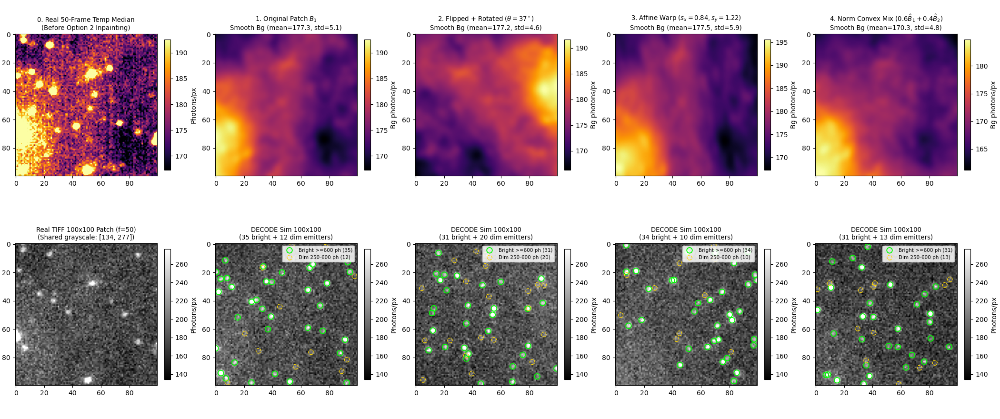

In [11]:
from scipy.ndimage import rotate, affine_transform

# --- 1. Full-FOV (684 x 428) 50-Frame Sliding-Window Option 2 Smooth Background ---
full_tif_path = project / 'data/low_density_examples/RegistrationCheck_LowDensity_GapT_Exp1_GapT_SealG_F3.tif'
center_frame = 50  # Same frame_index = 50 as Section 1, 3 & 5
win_len = 50

with tifffile.TiffFile(full_tif_path) as tif:
    s_f = center_frame - win_len // 2
    full_stack_adu = np.stack([tif.pages[i].asarray() for i in range(s_f, s_f + win_len)]).astype(np.float32)
    full_frame_adu = tif.pages[center_frame].asarray().astype(np.float32)

mid_w = full_stack_adu.shape[2] // 2  # Active right channel (684 x 428)
full_stack_phot = (full_stack_adu[:, :, mid_w:] - 400.0) * conv_factor
full_frame_phot = (full_frame_adu[:, mid_w:] - 400.0) * conv_factor
full_t_med = np.median(full_stack_phot, axis=0)
full_bg_smooth, _, _, _, _ = extract_bg_option2(full_t_med)

P = 100
# Exact 100x100 crop from Section 5: fov_y0=220 + r_top=70 -> y=290..390 (cy=340), fov_x0=86 + r_left=110 -> x=196..296 (cx=246)
cy, cx = 340, 246
real_patch_100 = full_frame_phot[cy - P // 2 : cy + P // 2, cx - P // 2 : cx + P // 2].copy()
tmed_patch_100 = full_t_med[cy - P // 2 : cy + P // 2, cx - P // 2 : cx + P // 2].copy()
patch_orig = full_bg_smooth[cy - P // 2 : cy + P // 2, cx - P // 2 : cx + P // 2].copy()

# --- 2. Augmentation 1: Coin-Flip Horizontal Reflection + Continuous Rotation (sqrt(2)-Expanded 142x142 Window) ---
P_rot_src = int(np.ceil(P * np.sqrt(2)))  # 142 x 142
half_rot = P_rot_src // 2
src_rot = full_bg_smooth[cy - half_rot : cy + half_rot, cx - half_rot : cx + half_rot].copy()
coin_flip = True  # Horizontal reflection coin flip
if coin_flip:
    src_rot = np.fliplr(src_rot)
theta_deg = 37.0
rot_full = rotate(src_rot, angle=theta_deg, reshape=False, order=3, mode='nearest')
c_r = rot_full.shape[0] // 2
patch_rotated = rot_full[c_r - P // 2 : c_r + P // 2, c_r - P // 2 : c_r + P // 2].copy()

# --- 3. Augmentation 2: Affine Warp (Stretch s_x, s_y in [0.75, 1.35] + Shear psi in [-15, +15] deg) ---
P_aff_src = 180
half_aff = P_aff_src // 2
src_aff = full_bg_smooth[cy - half_aff : cy + half_aff, cx - half_aff : cx + half_aff].copy()
s_y, s_x = 1.22, 0.84
psi_y_deg, psi_x_deg = 11.0, -9.0
A_forward = np.array([
    [s_y, np.tan(np.deg2rad(psi_x_deg))],
    [np.tan(np.deg2rad(psi_y_deg)), s_x]
])
A_inv = np.linalg.inv(A_forward)
center_aff = np.array([half_aff, half_aff], dtype=np.float64)
offset_aff = center_aff - A_inv @ center_aff
aff_full = affine_transform(src_aff, matrix=A_inv, offset=offset_aff, order=3, mode='nearest')
patch_affine = aff_full[half_aff - P // 2 : half_aff + P // 2, half_aff - P // 2 : half_aff + P // 2].copy()

# --- 4. Augmentation 3: Normalised Convex Combination -> Re-Scaled to Physical Photon Units ---
cy2, cx2 = 210, 275
patch_second = full_bg_smooth[cy2 - P // 2 : cy2 + P // 2, cx2 - P // 2 : cx2 + P // 2].copy()
lam = 0.60
# Step A: Normalise each patch to zero-mean, unit-variance first
b1_norm = (patch_orig - patch_orig.mean()) / (patch_orig.std() + 1e-6)
b2_norm = (patch_second - patch_second.mean()) / (patch_second.std() + 1e-6)
# Step B: Convex combination in normalised shape space + variance-preservation re-normalisation
bmix_norm = lam * b1_norm + (1.0 - lam) * b2_norm
bmix_norm = bmix_norm / (bmix_norm.std() + 1e-6)
# Step C: Scale back up to target physical mean & std (interpolated or sampled from empirical distribution)
mu_target = lam * patch_orig.mean() + (1.0 - lam) * patch_second.mean()
sig_target = lam * patch_orig.std() + (1.0 - lam) * patch_second.std()
patch_convex = np.maximum(mu_target + sig_target * bmix_norm, 1.0).astype(np.float32)

# --- 5. Convert Each Smooth Background Patch into an Actual DECODE Simulation Frame ---
aug_patches = [
    ('1. Original Patch $B_1$', patch_orig),
    (f'2. Flipped + Rotated ($\\theta={theta_deg:.0f}^\\circ$)', patch_rotated),
    (f'3. Affine Warp ($s_x={s_x}, s_y={s_y}$)', patch_affine),
    (f'4. Norm Convex Mix (${lam:.1f} \\hat{{B}}_1 + {1-lam:.1f} \\hat{{B}}_2$)', patch_convex),
]

p_sim = decode.utils.param_io.load_params(str(project / 'experimental_data_workflow' / 'param_run.yaml'))
p_sim.InOut.calibration_file = str(own_cal_path)
p_sim.Hardware.device = 'cpu'
p_sim.Hardware.device_simulation = 'cpu'
p_sim.Camera.baseline = 400.0
p_sim.Camera.e_per_adu = 0.46
p_sim.Camera.em_gain = None
p_sim.Camera.qe = 0.8
p_sim.Camera.read_sigma = 1.6
p_sim.Camera.spur_noise = 0.0
p_sim.Camera.px_size = [117.0, 117.0]
p_sim.Camera.convert2photons = True
p_sim.Simulation.mode = 'acquisition'
p_sim.Simulation.img_size = [P, P]
p_sim.Simulation.psf_extent = [[-0.5, P - 0.5], [-0.5, P - 0.5], None]
p_sim.Simulation.emitter_extent = [[-0.5, P - 0.5], [-0.5, P - 0.5], [-200.0, 200.0]]
base_density = 380.0 / (256.0 * 256.0)  # Exact Section 3 & 5 emitter density (58.0 emitters per 100x100 patch)
p_sim.Simulation.emitter_av = round(base_density * P * P, 1)
p_sim.Simulation.intensity_mu_sig = [1800.0, 750.0]
p_sim.Simulation.lifetime_avg = 1.0
p_sim.HyperParameter.pseudo_ds_size = 0
p_sim.TestSet.test_size = 0
p_sim.TestSet.frame_extent = p_sim.Simulation.psf_extent
p_sim.TestSet.img_size = [P, P]

sim_base, _ = setup_random_simulation(p_sim)

fig, axes = plt.subplots(2, 5, figsize=(21, 8.8), constrained_layout=True)

# Shared grayscale display window identical to Section 5 (central 256x256 FOV [p1, p99.5] = [138, 277] photons/px)
vmin_shared, vmax_shared = np.percentile(full_frame_phot[220:476, 86:342], [1, 99.5])

# Column 0: Real Reference (Top = 50-Frame Temporal Median, Bottom = Real Frame f=250)
im_rtm = axes[0, 0].imshow(tmed_patch_100, cmap='inferno', vmin=patch_orig.min(), vmax=patch_orig.max())
axes[0, 0].set_title(f'0. Real 50-Frame Temp Median\n(Before Option 2 Inpainting)', fontsize=9.5)
fig.colorbar(im_rtm, ax=axes[0, 0], label='Photons/px', fraction=0.046)

im_real = axes[1, 0].imshow(real_patch_100, cmap='gray', vmin=vmin_shared, vmax=vmax_shared)
axes[1, 0].set_title(f'Real TIFF 100x100 Patch (f={center_frame})\n(Shared grayscale: [{vmin_shared:.0f}, {vmax_shared:.0f}])', fontsize=9.5)
fig.colorbar(im_real, ax=axes[1, 0], label='Photons/px', fraction=0.046)

np.random.seed(42)
torch.manual_seed(42)

for idx, (title_str, bg_patch) in enumerate(aug_patches):
    col = idx + 1
    # Top Row: Smooth Augmented Background Map
    im_bg = axes[0, col].imshow(bg_patch, cmap='inferno')
    axes[0, col].set_title(f'{title_str}\nSmooth Bg (mean={bg_patch.mean():.1f}, std={bg_patch.std():.1f})', fontsize=9.5)
    fig.colorbar(im_bg, ax=axes[0, col], label='Bg photons/px', fraction=0.046)

    # Bottom Row: Exact DECODE Simulation using this exact 100x100 background patch
    sim_aug = decode.simulation.simulator.Simulation(
        psf=sim_base.psf,
        em_sampler=sim_base.em_sampler,
        background=EmpiricalBackground(bg_patch, random_crop_and_augment=False),
        noise=sim_base.noise,
        frame_range=[0, 0],
    )
    em_a, frames_a, _ = sim_aug.sample()
    sim_frame = frames_a[0].detach().cpu().numpy()
    em_f0 = em_a.get_subset_frame(0, 0)

    # Separate bright active emitters (>=600 photons) from dim/partial-frame blinks (250-600 photons)
    bright_mask = em_f0.phot >= 600.0
    dim_mask = (em_f0.phot >= 250.0) & (em_f0.phot < 600.0)
    xyz_bright = em_f0.xyz_px[bright_mask].detach().cpu().numpy()
    xyz_dim = em_f0.xyz_px[dim_mask].detach().cpu().numpy()

    im_sim = axes[1, col].imshow(sim_frame, cmap='gray', vmin=vmin_shared, vmax=vmax_shared)
    if len(xyz_bright) > 0:
        axes[1, col].scatter(
            xyz_bright[:, 1], xyz_bright[:, 0],
            s=70, facecolors='none', edgecolors='lime', linewidths=1.3,
            label=f'Bright >=600 ph ({len(xyz_bright)})'
        )
    if len(xyz_dim) > 0:
        axes[1, col].scatter(
            xyz_dim[:, 1], xyz_dim[:, 0],
            s=55, facecolors='none', edgecolors='gold', linewidths=1.0, linestyles='--' ,
            label=f'Dim 250-600 ph ({len(xyz_dim)})'
        )
    axes[1, col].legend(loc='upper right', fontsize=7.5, framealpha=0.85)
    axes[1, col].set_title(f'DECODE Sim 100x100\n({len(xyz_bright)} bright + {len(xyz_dim)} dim emitters)', fontsize=9.5)
    fig.colorbar(im_sim, ax=axes[1, col], label='Photons/px', fraction=0.046)

plt.show()